# 3장 1강: 편향-분산 트레이드오프와 과적합/과소적합 진단

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 모델 복잡도와 과적합/과소적합의 관계를 확인합니다.

- 모델이 너무 단순할 때 나타나는 **고편향(과소적합)** 상태를 확인합니다.
- 모델이 너무 복잡할 때 나타나는 **고분산(과적합)** 상태를 확인합니다.
- `learning_curve()`를 이용하여 학습곡선을 확인합니다.
- `validation_curve()`를 이용하여 모델 복잡도에 따른 Train / Validation 성능 변화를 확인합니다.
- `train-valid gap`을 이용하여 모델 상태를 진단합니다.
- 진단 결과에 맞는 대응 전략을 선택합니다.

> 이 실습에서는 3장 1강 교안에서 다룬 편향-분산, 학습곡선, 검증곡선, train-valid gap, 과적합/과소적합 대응 전략만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- numpy
- matplotlib
- scikit-learn
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택의 여러 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

이번 강의의 목적은 예측 성능 자체를 최대화하는 것이 아니라 **모델 복잡도에 따라 Train / Validation 성능이 어떻게 달라지는지 진단하는 것**입니다.

### 사용할 특성

결측치 처리 자체가 이번 강의의 학습 목표가 아니므로, 결측치가 없는 숫자형 특성 중 일부만 사용합니다.

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `TotalBsmtSF`
- `1stFlrSF`
- `YearBuilt`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 특성과 예측 대상을 선택합니다.
3. 결측치가 없는지 확인합니다.
4. 데이터 크기와 기초 통계량을 확인합니다.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import learning_curve, validation_curve

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "1stFlrSF",
    "YearBuilt"
]

X = house[features]
y = house["SalePrice"]

print("X 크기:", X.shape)
print("y 크기:", y.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

print("\n[기초 통계량]")
display(X.describe())

X 크기: (1460, 6)
y 크기: (1460,)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
TotalBsmtSF,0
1stFlrSF,0
YearBuilt,0



[기초 통계량]


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,1stFlrSF,YearBuilt
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,6.099315,1515.463699,1.767123,1057.429452,1162.626712,1971.267808
std,1.382997,525.480383,0.747315,438.705324,386.587738,30.202904
min,1.000000,334.000000,0.000000,0.000000,334.000000,1872.000000
25%,5.000000,1129.500000,1.000000,795.750000,882.000000,1954.000000
50%,6.000000,1464.000000,2.000000,991.500000,1087.000000,1973.000000
75%,7.000000,1776.750000,2.000000,1298.250000,1391.250000,2000.000000
max,10.000000,5642.000000,4.000000,6110.000000,4692.000000,2010.000000


---

# 필수 1. 학습곡선으로 과소적합과 과적합 진단

## 배경

학습곡선은 **학습 데이터의 양을 늘려가며 Train score와 Validation score가 어떻게 변하는지 확인하는 그래프**입니다.

이번 문제에서는 같은 Ames Housing 데이터에 대해 두 개의 결정트리를 비교합니다.

- `max_depth=2` → 복잡도가 낮은 모델
- `max_depth=None` → 깊이를 제한하지 않은 복잡한 모델

## 문제 1. `max_depth=2` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=2, random_state=42)`를 만듭니다.
2. `learning_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 학습 데이터 비율은 `np.linspace(0.1, 1.0, 6)`을 사용합니다.
5. 각 구간의 Train score와 Validation score 평균을 계산합니다.
6. 두 점수를 하나의 그래프에 표시합니다.
7. 두 곡선이 어디에서 수렴하는지 확인합니다.

### 확인 포인트

- 두 점수가 모두 낮은 수준에서 가까워지는가?
- 모델이 너무 단순한 상태인지 판단할 수 있는가?

,train_size,train,validation
0,116,0.701773,0.577790
1,327,0.669689,0.600452
2,537,0.664581,0.594019
3,747,0.653289,0.600512
4,957,0.645513,0.574357
5,1168,0.634121,0.602378


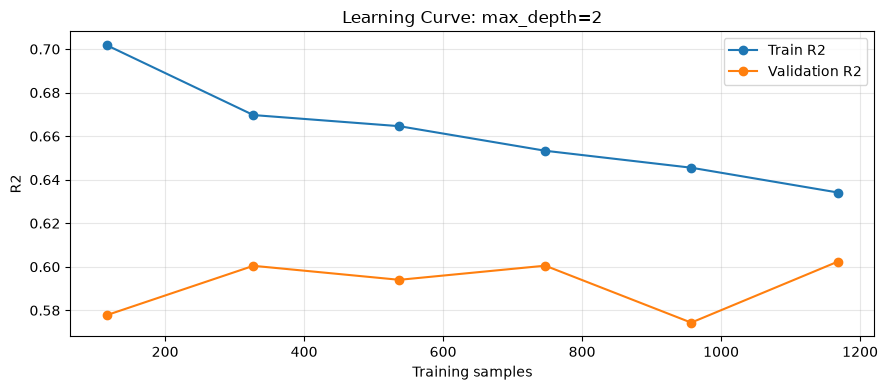

In [2]:
simple_model = DecisionTreeRegressor(max_depth=2,random_state=42)
simple_sizes, simple_train_scores, simple_valid_scores = learning_curve(
    simple_model,X,y,cv=5,train_sizes=np.linspace(0.1,1.0,6),scoring='r2')
simple_train_mean = simple_train_scores.mean(axis=1)
simple_valid_mean = simple_valid_scores.mean(axis=1)
simple_curve_df = pd.DataFrame({'train_size':simple_sizes,'train':simple_train_mean,'validation':simple_valid_mean})
display(simple_curve_df)
plt.figure(figsize=(9,4)); plt.plot(simple_sizes,simple_train_mean,'o-',label='Train R2')
plt.plot(simple_sizes,simple_valid_mean,'o-',label='Validation R2')
plt.xlabel('Training samples'); plt.ylabel('R2'); plt.title('Learning Curve: max_depth=2')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Q1. `max_depth=2` 모델은 과소적합과 과적합 중 어느 쪽에 더 가깝다고 볼 수 있나요?

**답변:**  
과소적합(고편향)에 더 가깝습니다. 최대 학습 크기에서 Train R²=0.6341, Validation R²=0.6024로 두 점수가 비슷하지만 상대적으로 낮습니다. 깊이 2의 제한이 특성과 가격의 복잡한 관계를 충분히 표현하지 못합니다.

## 문제 2. `max_depth=None` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=None, random_state=42)`를 만듭니다.
2. 필수 1 문제 1과 동일한 방식으로 `learning_curve()`를 사용합니다.
3. Train score와 Validation score를 그래프로 나타냅니다.
4. 두 곡선 사이의 간격을 확인합니다.

### 확인 포인트

- Train score가 매우 높은가?
- Validation score와의 간격이 크게 유지되는가?
- 고분산(과적합) 신호를 확인할 수 있는가?

,train_size,train,validation
0,116,0.999905,0.589764
1,327,0.999966,0.704324
2,537,0.999860,0.715267
3,747,0.999848,0.669292
4,957,0.999826,0.684923
5,1168,0.999768,0.727192


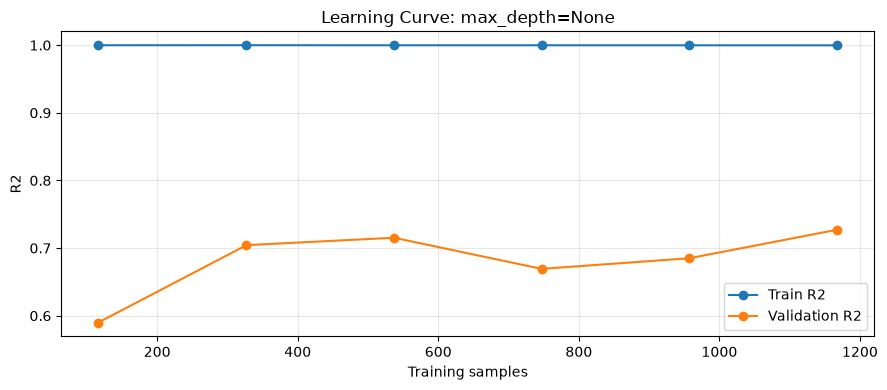

In [3]:
complex_model = DecisionTreeRegressor(max_depth=None,random_state=42)
complex_sizes, complex_train_scores, complex_valid_scores = learning_curve(
    complex_model,X,y,cv=5,train_sizes=np.linspace(0.1,1.0,6),scoring='r2')
complex_train_mean = complex_train_scores.mean(axis=1)
complex_valid_mean = complex_valid_scores.mean(axis=1)
complex_curve_df = pd.DataFrame({'train_size':complex_sizes,'train':complex_train_mean,'validation':complex_valid_mean})
display(complex_curve_df)
plt.figure(figsize=(9,4)); plt.plot(complex_sizes,complex_train_mean,'o-',label='Train R2')
plt.plot(complex_sizes,complex_valid_mean,'o-',label='Validation R2')
plt.xlabel('Training samples'); plt.ylabel('R2'); plt.title('Learning Curve: max_depth=None')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Q2. `max_depth=None` 모델에서 데이터를 더 추가하는 것이 도움이 될 가능성이 있는 이유는 무엇인가요?

**답변:**  
최대 학습 크기에서 Train R²=0.9998, Validation R²=0.7272로 간격이 큽니다. 더 많은 대표성 있는 학습 데이터는 특정 샘플에 대한 의존을 줄여 분산을 낮출 수 있습니다. 다만 개선을 보장하지 않으며 깊이 제한도 함께 검토합니다.

---

# 필수 2. 검증곡선과 train-valid gap으로 최적 복잡도 확인

## 배경

검증곡선은 **모델의 하이퍼파라미터를 바꿔가며 Train score와 Validation score의 변화를 확인하는 그래프**입니다.

이번 문제에서는 결정트리의 `max_depth`를 바꾸어 모델 복잡도를 조절합니다.

## 문제 1. `max_depth` 검증곡선을 만드세요.

### 요구사항

1. 다음 `max_depth` 후보를 사용합니다.

```python
param_range = [1, 2, 3, 4, 5, 8, 12, 20, None]
```

2. `validation_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 각 `max_depth`의 Train score와 Validation score 평균을 계산합니다.
5. `gap = train_mean - valid_mean`을 계산합니다.
6. `max_depth`, `train`, `validation`, `gap`을 DataFrame으로 만듭니다.
7. Train / Validation score를 하나의 그래프에 표시합니다.

### 확인 포인트

- 복잡도가 증가할수록 Train score가 어떻게 변하는가?
- Validation score는 어느 지점까지 좋아지고 이후 어떻게 변하는가?
- train-valid gap은 깊이가 커질수록 어떻게 변하는가?

,max_depth,train,validation,gap
0,1,0.454464,0.429791,0.024674
1,2,0.634121,0.602378,0.031743
2,3,0.733594,0.679087,0.054507
3,4,0.811466,0.733510,0.077956
4,5,0.862431,0.755587,0.106844
5,8,0.948189,0.770884,0.177305
6,12,0.989787,0.746059,0.243728
7,20,0.999686,0.735295,0.264391
8,None,0.999768,0.727192,0.272575


최고 평균 Validation R2의 max_depth: 8


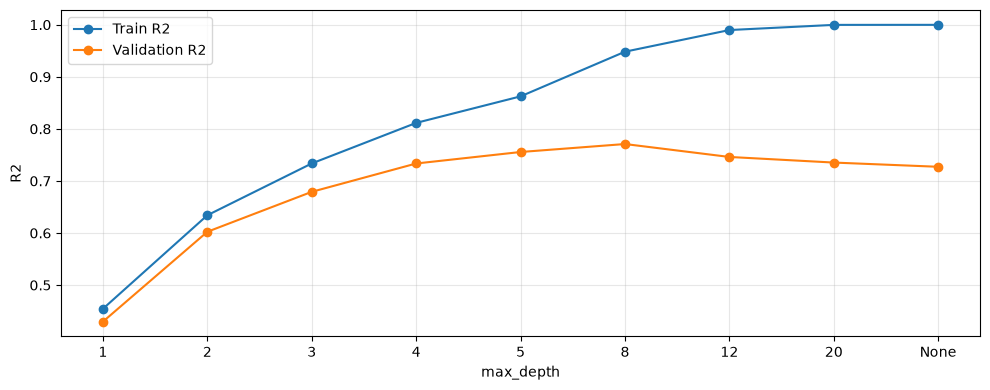

In [4]:
param_range = [1,2,3,4,5,8,12,20,None]
train_scores,valid_scores = validation_curve(DecisionTreeRegressor(random_state=42),X,y,
    param_name='max_depth',param_range=param_range,cv=5,scoring='r2')
train_mean = train_scores.mean(axis=1)
valid_mean = valid_scores.mean(axis=1)
gap_df = pd.DataFrame({'max_depth':pd.Series(param_range,dtype=object),
    'train':train_mean,'validation':valid_mean,'gap':train_mean-valid_mean})
display(gap_df)
best_idx = int(np.argmax(valid_mean))
print('최고 평균 Validation R2의 max_depth:',param_range[best_idx])
positions = np.arange(len(param_range))
plt.figure(figsize=(10,4)); plt.plot(positions,train_mean,'o-',label='Train R2')
plt.plot(positions,valid_mean,'o-',label='Validation R2')
plt.xticks(positions,[str(v) for v in param_range]); plt.xlabel('max_depth'); plt.ylabel('R2')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Q3. Validation score가 가장 높은 `max_depth`는 무엇인가요?

**답변:**  
후보 중 max_depth=8에서 평균 Validation R²가 0.7709로 가장 높습니다. 이 후보 집합과 cv=5에서의 결과이며, 독립 Test 성능이나 보편적인 최적 깊이는 아닙니다.

### Q4. `max_depth`가 매우 커질수록 train-valid gap이 커지는 이유는 무엇인가요?

**답변:**  
깊은 트리는 Train의 세부 패턴과 잡음까지 학습하여 Train 점수를 높이지만, 새로운 데이터에서 그 패턴이 재현되지 않아 Validation 점수는 같은 만큼 오르지 않습니다. 그래서 일반화 간격이 커집니다.

---

# 과제 1. 모델 상태를 진단하고 대응 전략 선택하기

## 배경

필수 실습에서는 학습곡선과 검증곡선을 이용해 모델의 상태를 확인했습니다.

이번 과제에서는 검증곡선 결과를 이용하여 세 가지 복잡도의 모델 상태를 직접 판단합니다.

> 과제는 필수 실습에서 확인한 결과를 해석하는 수준입니다.

## 문제

다음 세 모델을 확인하세요.

- `max_depth=1`
- `max_depth=8`
- `max_depth=None`

### 요구사항

1. 필수 2에서 만든 `gap_df`에서 세 모델의 Train score, Validation score, gap을 확인합니다.
2. 각 모델을 다음 중 하나로 진단합니다.
   - 과소적합
   - 비교적 적절한 복잡도
   - 과적합
3. 각 모델의 진단 근거를 Train score, Validation score, gap을 이용해 설명합니다.
4. 과소적합 또는 과적합 모델에 대해 교안에서 배운 대응 전략 중 적절한 방향을 하나 이상 작성합니다.

### 확인 포인트

- 점수가 낮고 gap이 작은 경우를 과소적합으로 해석할 수 있는가?
- Train score만 매우 높고 gap이 큰 경우를 과적합으로 해석할 수 있는가?
- Validation score가 높고 gap이 지나치게 크지 않은 지점을 적절한 후보로 볼 수 있는가?
- 진단 후에 대응 전략을 선택했는가?

In [6]:
selected_df = gap_df[gap_df['max_depth'].map(lambda value:value in (1,8) or value is None)].copy()
display(selected_df)
print('1: 낮은 점수와 작은 gap → 과소적합')
print('8: 깊이 무제한보다 개선되지만 gap이 남음 → 상대적으로 적절한 후보, 과적합 주의')
print('None: Train은 거의 1, Validation과 큰 gap → 과적합')

,max_depth,train,validation,gap
0,1,0.454464,0.429791,0.024674
5,8,0.948189,0.770884,0.177305
8,None,0.999768,0.727192,0.272575


1: 낮은 점수와 작은 gap → 과소적합
8: 깊이 무제한보다 개선되지만 gap이 남음 → 상대적으로 적절한 후보, 과적합 주의
None: Train은 거의 1, Validation과 큰 gap → 과적합


### Q5. 세 모델의 상태를 각각 진단하세요.

| max_depth | 진단 | 근거 |
|---|---|---|
| 1 | 과소적합 | Train R²=0.4545, Validation R²=0.4298, gap=0.0247. 점수가 낮고 간격이 작음 |
| 8 | 비교적 적절한 후보(과적합 주의) | Train R²=0.9482, Validation R²=0.7709, gap=0.1773. 무제한보다 검증 성능이 높으나 간격이 남음 |
| None | 과적합 | Train R²=0.9998, Validation R²=0.7272, gap=0.2726. Train만 거의 1이고 간격이 큼 |

### Q6. 과소적합 모델과 과적합 모델에 각각 어떤 대응 전략을 사용할 수 있나요?

**답변:**  
과소적합이면 트리 깊이를 늘려 복잡도를 높이거나 유용한 특성을 추가합니다. 과적합이면 max_depth를 낮추고 min_samples_leaf를 늘리는 등 복잡도를 제한하거나, 더 많은 대표성 있는 데이터를 확보합니다. 깊이 8도 gap이 남으므로 무조건 적절하다고 확정하지 않고 Train 내부 검증으로 판단합니다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 편향이 높은 모델은 일반적으로 과소적합과 과적합 중 어느 상태와 관련이 있나요?  
-> 과소적합입니다.

2. 분산이 높은 모델은 일반적으로 어느 상태와 관련이 있나요?  
-> 과적합입니다.

3. 학습곡선에서 Train과 Validation이 낮은 값에서 함께 수렴하면 어떤 상태인가요?  
-> 고편향에 따른 과소적합 신호입니다.

4. Train score는 매우 높지만 Validation score가 낮고 gap이 크다면 어떤 상태인가요?  
-> 고분산에 따른 과적합 신호입니다.

5. 검증곡선에서 Validation score가 가장 높은 지점은 어떤 의미를 가지나요?  
-> 검토한 후보 중 일반화 성능이 가장 좋은 복잡도 후보입니다.

6. 과적합과 과소적합을 진단하지 않고 바로 처방하면 안 되는 이유는 무엇인가요?  
-> 진단에 따라 복잡도를 늘리거나 줄이는 방향이 달라 잘못된 처방이 성능을 악화할 수 있습니다.